<a href="https://colab.research.google.com/github/Aditigk1203/ADITI-G-KRISHNAN/blob/main/EDA_PHASE2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#23BDS0054
#ADITI KRISHNAN
#EDA
#PHASE 2 PROJECT - EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("stars_type.csv")

print(df.head())
print(df.shape)
print(df.info())

   Temperature (K) Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)  \
0             3068           0.0024        0.1700                   16.12   
1             3042           0.0005        0.1542                   16.60   
2             2600           0.0003        0.1020                   18.70   
3             2800           0.0002        0.1600                   16.65   
4             1939         0.000138        0.1030                   20.06   

   Star type Star color Spectral Class  
0          0        Red              M  
1          0        Red              M  
2          0        Red              M  
3          0        Red              M  
4          0        Red              M  
(240, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/L

In [2]:
num_cols = [
    "Temperature (K)",
    "Luminosity(L/Lo)",
    "Radius(R/Ro)",
    "Absolute magnitude(Mv)"
]

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[num_cols].describe())

       Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)
count       240.000000        239.000000    240.000000              240.000000
mean      10497.462500     106164.045156    237.157781                4.382396
std        9552.425037     179104.259253    517.155763               10.532512
min        1939.000000          0.000080      0.008400              -11.920000
25%        3344.250000          0.000860      0.102750               -6.232500
50%        5776.000000          0.056000      0.762500                8.313000
75%       15055.500000     198000.000000     42.750000               13.697500
max       40000.000000     849420.000000   1948.500000               20.060000


# 1D STATISTICAL ANALYSIS

In [3]:
from scipy.stats import skew, kurtosis

x = df["Temperature (K)"]

stats = {
    "Mean": x.mean(),
    "Median": x.median(),
    "Minimum": x.min(),
    "Maximum": x.max(),
    "Range": x.max() - x.min(),
    "Variance": x.var(),
    "Standard Deviation": x.std(),
    "IQR": x.quantile(0.75) - x.quantile(0.25),
    "Skewness": skew(x.dropna()),
    "Kurtosis": kurtosis(x.dropna())
}

print(pd.Series(stats))

Mean                  1.049746e+04
Median                5.776000e+03
Minimum               1.939000e+03
Maximum               4.000000e+04
Range                 3.806100e+04
Variance              9.124882e+07
Standard Deviation    9.552425e+03
IQR                   1.171125e+04
Skewness              1.313294e+00
Kurtosis              8.342841e-01
dtype: float64


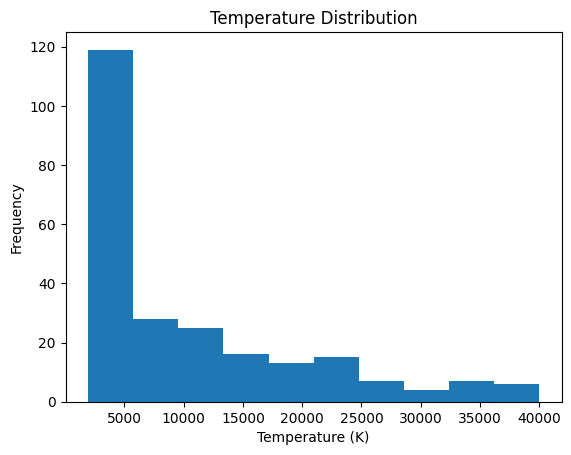

In [4]:
plt.hist(df["Temperature (K)"], bins=10)
plt.xlabel("Temperature (K)")
plt.ylabel("Frequency")
plt.title("Temperature Distribution")
plt.show()

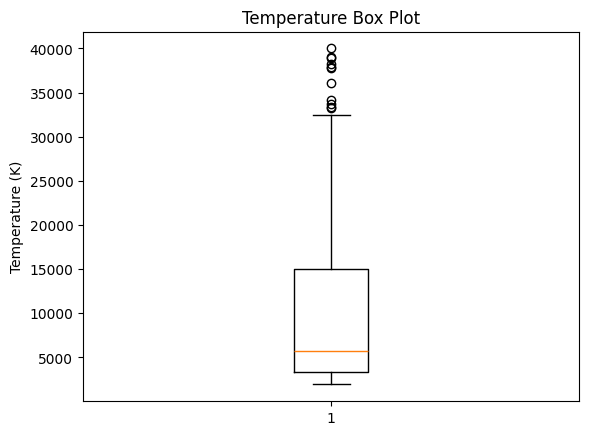

In [5]:
plt.boxplot(df["Temperature (K)"].dropna())
plt.ylabel("Temperature (K)")
plt.title("Temperature Box Plot")
plt.show()

In [6]:
freq = df["Star color"].value_counts()

print(freq)

Star color
Red                   110
Blue                   54
Blue-white             26
Blue White             10
yellow-white            8
White                   7
Yellowish White         3
Blue white              3
white                   3
Orange                  2
Whitish                 2
yellowish               2
Pale yellow orange      1
White-Yellow            1
Blue                    1
Yellowish               1
Orange-Red              1
Blue white              1
Blue-White              1
Name: count, dtype: int64


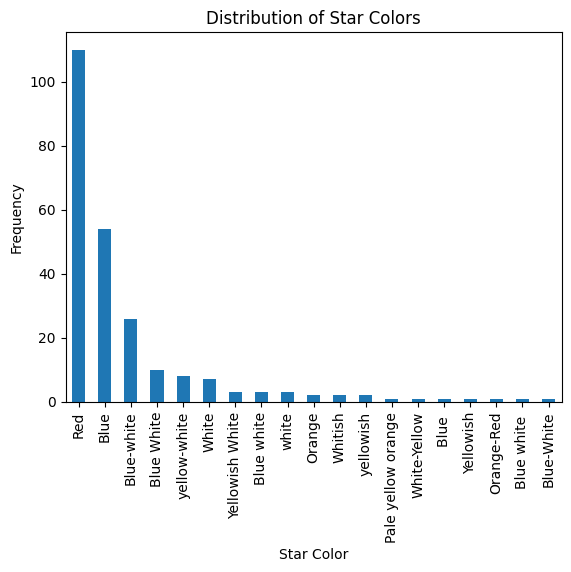

In [7]:
freq.plot(kind="bar")
plt.xlabel("Star Color")
plt.ylabel("Frequency")
plt.title("Distribution of Star Colors")
plt.show()

# 2D STATISTICAL ANALYSIS

In [8]:
x = df["Temperature (K)"]
y = df["Luminosity(L/Lo)"]

print("Pearson Correlation:")
print(x.corr(y))

Pearson Correlation:
0.3858373129295435


In [9]:
print("Spearman Correlation:")
print(x.corr(y, method="spearman"))

Spearman Correlation:
0.4782014780125029


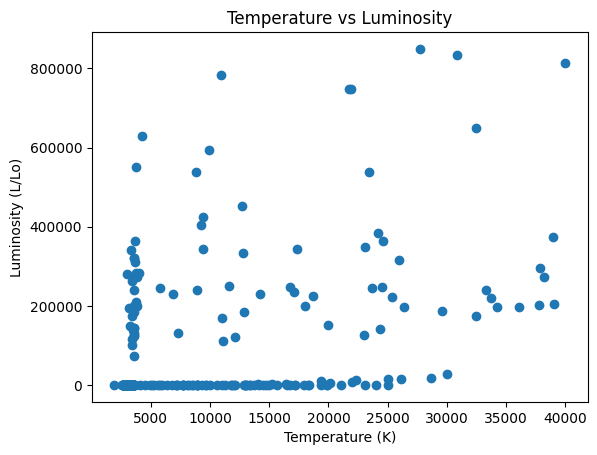

In [10]:
plt.scatter(x, y)
plt.xlabel("Temperature (K)")
plt.ylabel("Luminosity (L/Lo)")
plt.title("Temperature vs Luminosity")
plt.show()

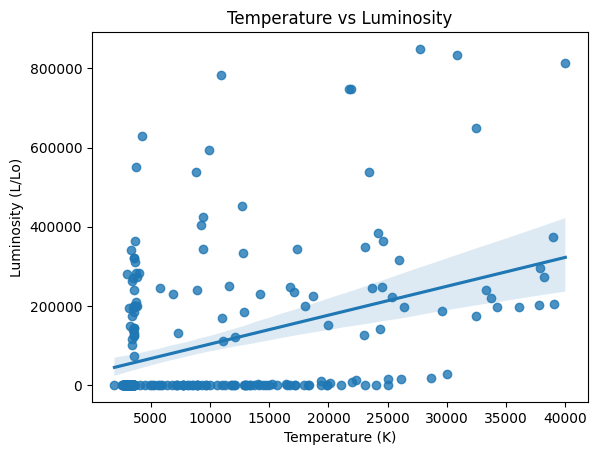

In [11]:
sns.regplot(x=x, y=y)

plt.xlabel("Temperature (K)")
plt.ylabel("Luminosity (L/Lo)")
plt.title("Temperature vs Luminosity")
plt.show()

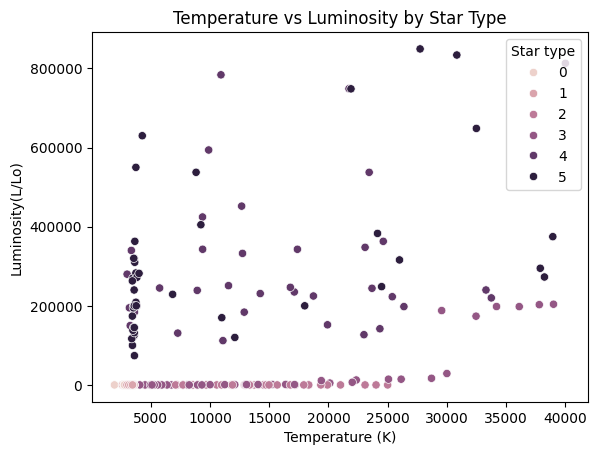

In [12]:
sns.scatterplot(
    data=df,
    x="Temperature (K)",
    y="Luminosity(L/Lo)",
    hue="Star type"
)

plt.title("Temperature vs Luminosity by Star Type")
plt.show()

In [13]:
print(df.groupby("Star color")["Temperature (K)"].mean())

Star color
Blue                  22015.425926
Blue                  19860.000000
Blue White            14638.900000
Blue white            10135.333333
Blue white            11900.000000
Blue-White             8945.000000
Blue-white            18669.923077
Orange                 4018.000000
Orange-Red             5112.000000
Pale yellow orange     7230.000000
Red                    3290.454545
White                  8545.857143
White-Yellow           7100.000000
Whitish                8876.000000
Yellowish              4980.000000
Yellowish White       10826.666667
white                 12460.666667
yellow-white           6466.250000
yellowish              4301.500000
Name: Temperature (K), dtype: float64


In [14]:
print(df.groupby("Star color")["Temperature (K)"].agg(
    ["mean", "median", "std"]
))

                            mean   median          std
Star color                                            
Blue                22015.425926  20471.5  9616.112072
Blue                19860.000000  19860.0          NaN
Blue White          14638.900000  13760.0  4305.593892
Blue white          10135.333333   8924.0  2411.169288
Blue white          11900.000000  11900.0          NaN
Blue-White           8945.000000   8945.0          NaN
Blue-white          18669.923077  18270.0  6890.934218
Orange               4018.000000   4018.0   380.423448
Orange-Red           5112.000000   5112.0          NaN
Pale yellow orange   7230.000000   7230.0          NaN
Red                  3290.454545   3324.0   494.527235
White                8545.857143   8500.0  1136.878098
White-Yellow         7100.000000   7100.0          NaN
Whitish              8876.000000   8876.0  1165.311975
Yellowish            4980.000000   4980.0          NaN
Yellowish White     10826.666667  11790.0  2773.451520
white     

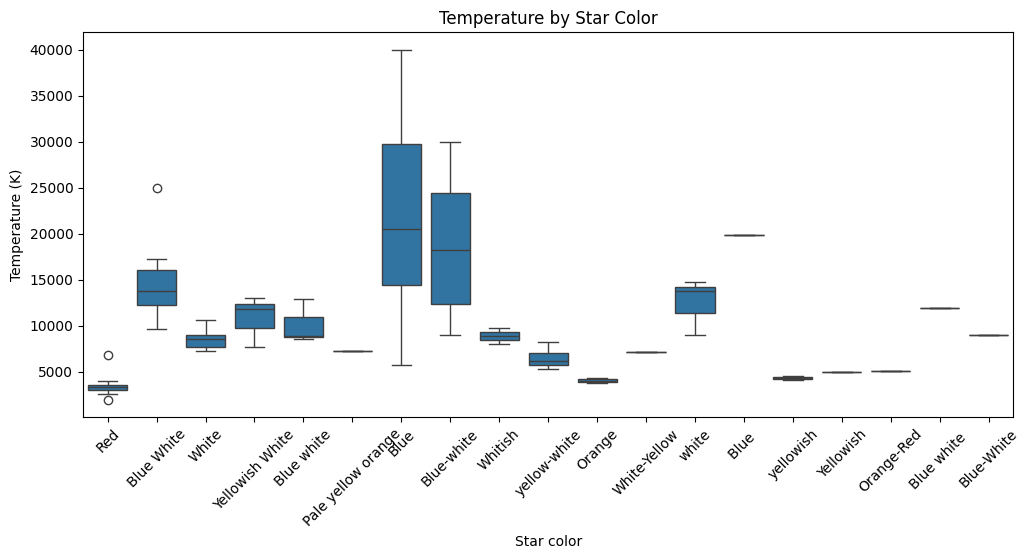

In [15]:
plt.figure(figsize=(12,5))

sns.boxplot(
    data=df,
    x="Star color",
    y="Temperature (K)"
)

plt.xticks(rotation=45)
plt.title("Temperature by Star Color")
plt.show()

# 3D STATISTICAL Analysis

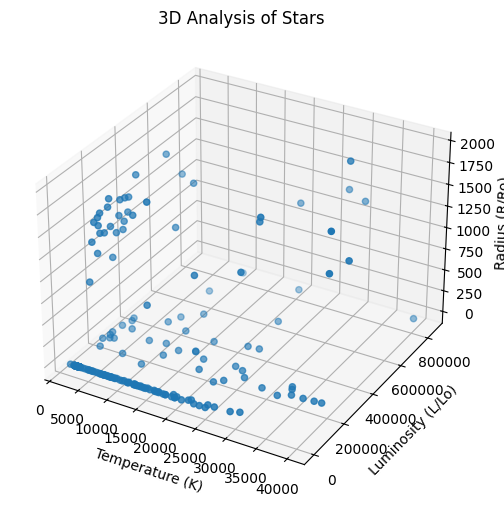

In [16]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    df["Temperature (K)"],
    df["Luminosity(L/Lo)"],
    df["Radius(R/Ro)"]
)

ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Luminosity (L/Lo)")
ax.set_zlabel("Radius (R/Ro)")

ax.set_title("3D Analysis of Stars")

plt.show()

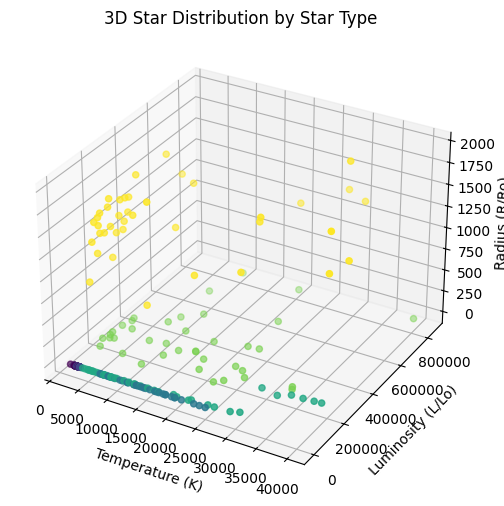

In [17]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    df["Temperature (K)"],
    df["Luminosity(L/Lo)"],
    df["Radius(R/Ro)"],
    c=df["Star type"],
    cmap="viridis"
)

ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Luminosity (L/Lo)")
ax.set_zlabel("Radius (R/Ro)")

ax.set_title("3D Star Distribution by Star Type")

plt.show()

In [18]:
corr = df[num_cols].corr()

print(corr)

                        Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  \
Temperature (K)                1.000000          0.385837      0.064216   
Luminosity(L/Lo)               0.385837          1.000000      0.530601   
Radius(R/Ro)                   0.064216          0.530601      1.000000   
Absolute magnitude(Mv)        -0.420261         -0.691141     -0.608728   

                        Absolute magnitude(Mv)  
Temperature (K)                      -0.420261  
Luminosity(L/Lo)                     -0.691141  
Radius(R/Ro)                         -0.608728  
Absolute magnitude(Mv)                1.000000  


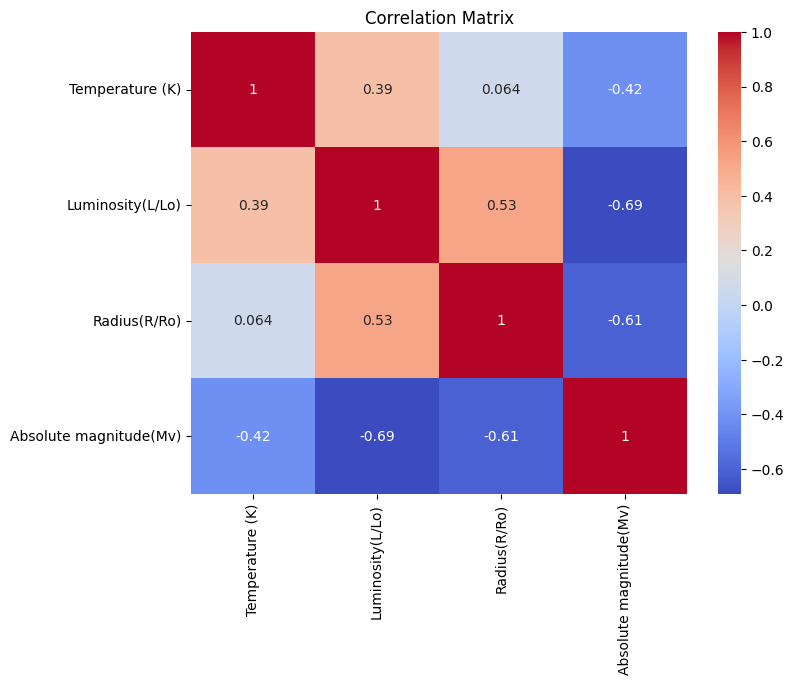

In [19]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

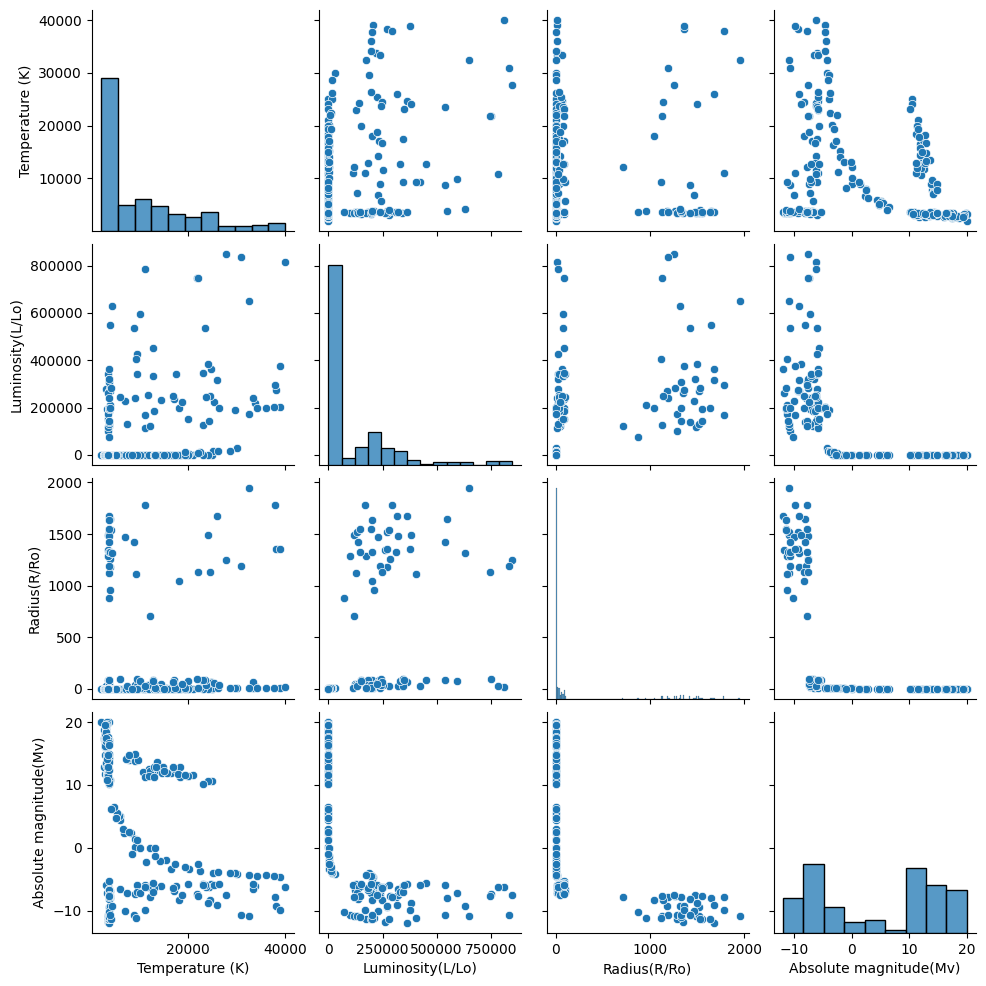

In [20]:
sns.pairplot(df[num_cols])

plt.show()

# K-MEANS CLUSTERING

In [22]:
X = df[num_cols].dropna()

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [24]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=123, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

In [25]:
kmeans = KMeans(
    n_clusters=6,
    random_state=123,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

print(clusters)

[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 1 5 5 5 1 1 5 5 1 5 4 4 1 1 1 1 1
 1 1 1 0 0 0 0 0 0 0 0 0 4 3 3 3 3 3 3 3 3 3 3 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 1 5 1 1 5 1 1 1 1 1 5 5 1 1 1 1 1 1 4 4 2 4 0 0 0 4 0 4 3 3
 3 3 3 3 3 3 3 3 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 1 1 1 1 1 5 1 1 5
 1 4 1 1 1 4 4 4 4 1 4 4 0 0 0 0 0 4 4 0 0 3 3 3 2 3 3 3 3 0 2 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 1 1 1 1 1 1 1 1 1 1 4 1 1 4 4 4 1 1 1 1 4 0 0
 0 0 0 0 0 4 2 2 2 2 2 2 2 2 3 3 2]


In [26]:
clustered = X.copy()

clustered["Cluster"] = clusters

print(clustered.head())

   Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)  \
0             3068          0.002400        0.1700                   16.12   
1             3042          0.000500        0.1542                   16.60   
2             2600          0.000300        0.1020                   18.70   
3             2800          0.000200        0.1600                   16.65   
4             1939          0.000138        0.1030                   20.06   

   Cluster  
0        5  
1        5  
2        5  
3        5  
4        5  


In [27]:
print(clustered["Cluster"].value_counts())

Cluster
5    93
1    54
3    29
0    28
4    23
2    12
Name: count, dtype: int64


In [28]:
print(kmeans.cluster_centers_)

[[-0.06764391  1.00892011 -0.31515033 -1.0434644 ]
 [ 0.30393242 -0.59200176 -0.45699404  0.23286106]
 [ 2.1158119   2.45173065  1.86616847 -1.24149935]
 [-0.58534574  0.81044904  2.18364322 -1.36700793]
 [ 1.85115287  0.26243373 -0.41177746 -0.88558021]
 [-0.7044038  -0.59399391 -0.45964415  0.98443089]]


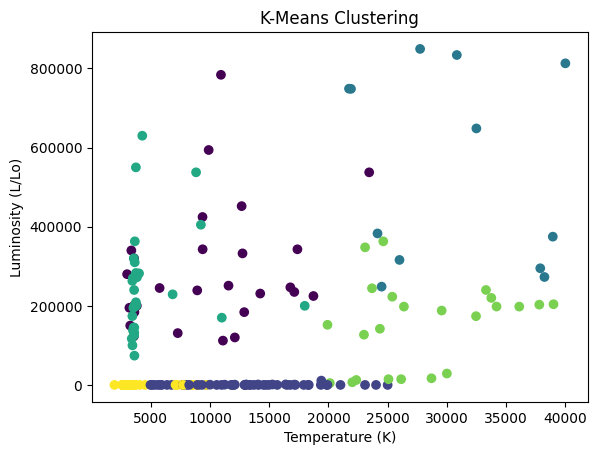

In [29]:
plt.scatter(
    X["Temperature (K)"],
    X["Luminosity(L/Lo)"],
    c=clusters,
    cmap="viridis"
)

plt.xlabel("Temperature (K)")
plt.ylabel("Luminosity (L/Lo)")
plt.title("K-Means Clustering")
plt.show()

# HIERARCHICAL CLUSTERING

In [30]:
X = df[num_cols].dropna()

In [31]:
X_scaled = scaler.fit_transform(X)

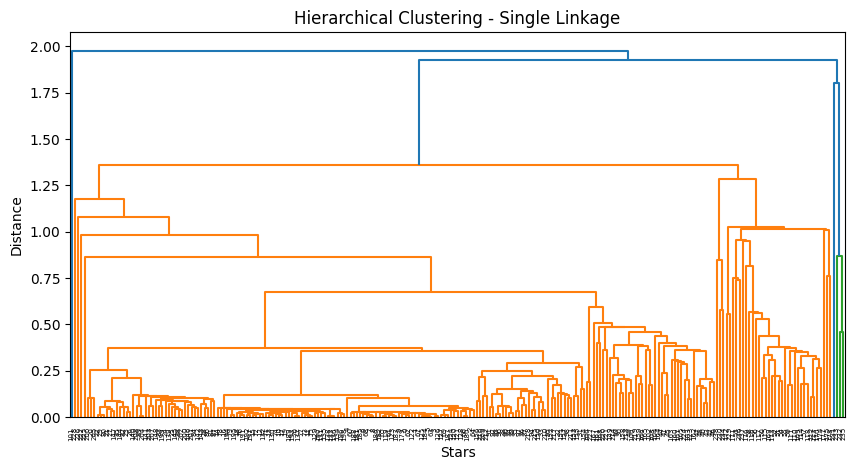

In [32]:
#Single Linkage
from scipy.cluster.hierarchy import linkage, dendrogram

single = linkage(
    X_scaled,
    method="single",
    metric="euclidean"
)

plt.figure(figsize=(10,5))

dendrogram(single)

plt.title("Hierarchical Clustering - Single Linkage")
plt.xlabel("Stars")
plt.ylabel("Distance")

plt.show()

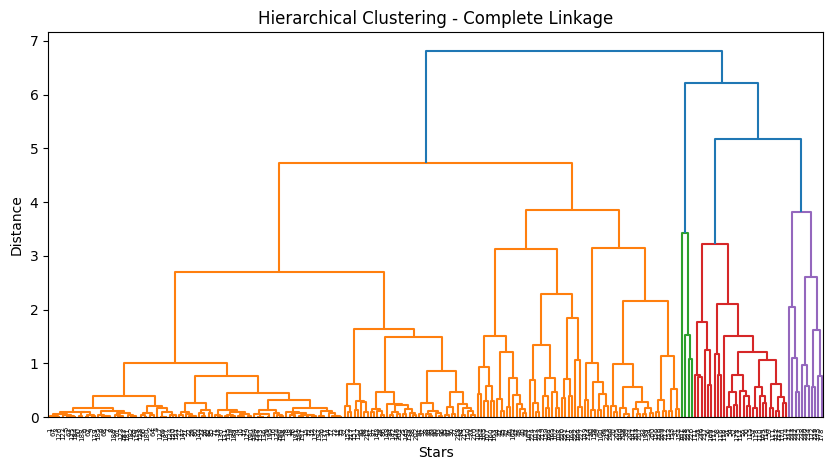

In [33]:
#COMPLETE LINKAGE
complete = linkage(
    X_scaled,
    method="complete",
    metric="euclidean"
)

plt.figure(figsize=(10,5))

dendrogram(complete)

plt.title("Hierarchical Clustering - Complete Linkage")
plt.xlabel("Stars")
plt.ylabel("Distance")

plt.show()

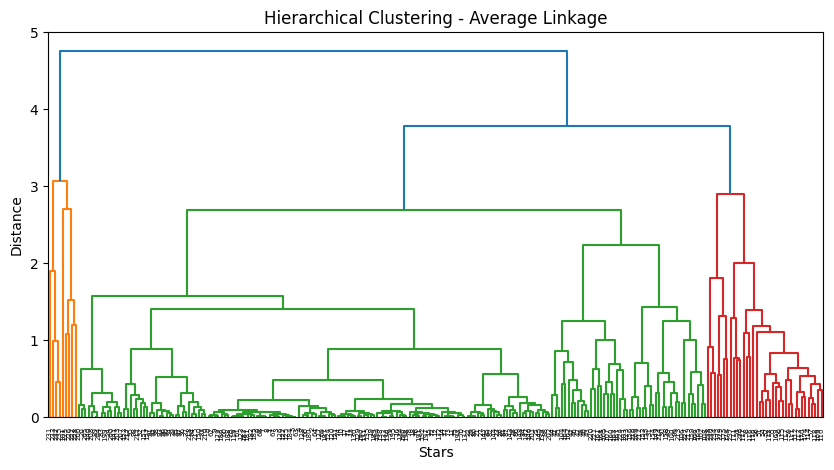

In [34]:
#AVERAGE LINKAGE
average = linkage(
    X_scaled,
    method="average",
    metric="euclidean"
)

plt.figure(figsize=(10,5))

dendrogram(average)

plt.title("Hierarchical Clustering - Average Linkage")
plt.xlabel("Stars")
plt.ylabel("Distance")

plt.show()

In [35]:
from scipy.cluster.hierarchy import fcluster

cluster_single = fcluster(single, 3, criterion="maxclust")
cluster_complete = fcluster(complete, 3, criterion="maxclust")
cluster_average = fcluster(average, 3, criterion="maxclust")

In [36]:
# 3 HIERARCHICAL CLUSTERS
print("Single Linkage:")
print(cluster_single[:20])

print("\nComplete Linkage:")
print(cluster_complete[:20])

print("\nAverage Linkage:")
print(cluster_average[:20])

Single Linkage:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Complete Linkage:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Average Linkage:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [37]:
#CLUSTER ASSIGNMENTS
print("Single Linkage:")
print(pd.Series(cluster_single).value_counts())

print("\nComplete Linkage:")
print(pd.Series(cluster_complete).value_counts())

print("\nAverage Linkage:")
print(pd.Series(cluster_average).value_counts())

Single Linkage:
1    234
2      4
3      1
Name: count, dtype: int64

Complete Linkage:
1    195
3     40
2      4
Name: count, dtype: int64

Average Linkage:
2    194
3     36
1      9
Name: count, dtype: int64


In [38]:
#NUMBER OF SAMPLES IN EACH CLUSTER
print("Single Linkage:")
print(pd.Series(cluster_single).value_counts())

print("\nComplete Linkage:")
print(pd.Series(cluster_complete).value_counts())

print("\nAverage Linkage:")
print(pd.Series(cluster_average).value_counts())

Single Linkage:
1    234
2      4
3      1
Name: count, dtype: int64

Complete Linkage:
1    195
3     40
2      4
Name: count, dtype: int64

Average Linkage:
2    194
3     36
1      9
Name: count, dtype: int64
